# 06 – Biais du survivant : univers biaisé vs point-in-time

Les notebooks 02 à 05 backtestent la stratégie sur **50 grandes capitalisations d'aujourd'hui**. Problème : ce sont les **gagnants connus a posteriori**. Les entreprises jadis dans le S&P 500 puis sorties (rachats, faillites, relégations) — BBBY, CELG, CERN, ANTM… — manquent. Ce sont précisément les perdants, et les ignorer **embellit les résultats** : c'est le *biais du survivant*.

Ici on corrige le biais avec un **univers point-in-time** (`src/universe.py`) : à chaque mois, on ne retient que les actions **réellement membres du S&P 500 à cette date**. On compare alors, sur la **même période**, le backtest biaisé et le backtest corrigé.

> ⚠️ Ce notebook suppose que les prix de l'univers historique ont été ingérés :
> basculer `config.yaml` sur `universe: sp500_historical` puis lancer
> `python src/pipeline.py` (ou le DAG Airflow). Couverture yfinance ~82 % des 708 tickers.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from analytics import load_prices
from backtest import backtest_momentum, equity_curve, performance
from universe import load_membership

plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:.3f}'.format

BIAIS, CORR = '#eb6834', '#2a78d6'  # biaisé (orange) vs corrigé (bleu)

## 1. Les deux univers

- **Biaisé** : les 50 tickers figés de `config.yaml` (les leaders d'aujourd'hui).
- **Corrigé** : l'appartenance historique, avec un masque point-in-time mois par mois.


In [2]:
cfg = yaml.safe_load((ROOT / 'config.yaml').read_text())
db = ROOT / cfg['db_path']

prices = load_prices(db)
membership = load_membership(db)

# univers biaisé : les 50 d'aujourd'hui effectivement présents dans les prix
biais_tickers = [t for t in cfg['tickers'] if t in prices.columns]

print(f"Prix disponibles      : {prices.shape[1]} tickers  "
      f"({prices.index.min().date()} -> {prices.index.max().date()})")
print(f"Univers biaisé        : {len(biais_tickers)} tickers (figés)")
print(f"Univers corrigé       : {membership.shape[1]} tickers vus dans l'indice depuis 2015")
print(f"Membres par mois      : ~{int(membership.sum(axis=1).median())} (médiane)")

Prix disponibles      : 584 tickers  (2015-01-02 -> 2026-11-13)
Univers biaisé        : 50 tickers (figés)
Univers corrigé       : 708 tickers vus dans l'indice depuis 2015
Membres par mois      : ~498 (médiane)


## 2. Les deux backtests

Même moteur (`backtest_momentum`, top 20 %, coûts 10 pb), seul l'univers change. Le backtest corrigé reçoit le **masque d'appartenance** : stratégie *et* benchmark ne tiennent à chaque date que les membres de l'indice à cette date.


In [3]:
bt_biais = backtest_momentum(prices[biais_tickers], frac=0.2, cost_bps=10)
bt_corr = backtest_momentum(prices, frac=0.2, cost_bps=10, membership=membership)

print("Mois couverts — biaisé :", bt_biais.shape[0], "| corrigé :", bt_corr.shape[0])

Mois couverts — biaisé : 130 | corrigé : 116


## 3. Comparaison à période alignée

Les deux backtests ne couvrent pas exactement la même fenêtre (l'appartenance s'arrête à la dernière photo disponible). Pour une comparaison **honnête**, on restreint les deux séries à leur **période commune** et on recalcule les métriques dessus.


In [4]:
common = bt_biais.index.intersection(bt_corr.index)
print(f"Période commune : {common.min().date()} -> {common.max().date()} ({len(common)} mois)")

def metrics(bt, col):
    return performance(bt.loc[common, col])

table = pd.DataFrame({
    ('Momentum', 'biaisé'):  metrics(bt_biais, 'strategy'),
    ('Momentum', 'corrigé'): metrics(bt_corr, 'strategy'),
    ('Marché',   'biaisé'):  metrics(bt_biais, 'benchmark'),
    ('Marché',   'corrigé'): metrics(bt_corr, 'benchmark'),
}).T
table.index.names = ['stratégie', 'univers']
table

Période commune : 2016-02-29 -> 2025-09-30 (116 mois)


rendement_annuel  volatilite_annuelle  sharpe  max_drawdown
stratégie univers                                                             
Momentum  biaisé              0.212                0.172   1.207        -0.179
          corrigé             0.123                0.159   0.813        -0.196
Marché    biaisé              0.191                0.147   1.270        -0.222
          corrigé             0.134                0.169   0.834        -0.269

## 4. Courbes de capital (1 $ investi, période commune)

À gauche la stratégie momentum, à droite le marché équipondéré. Dans les deux cas, la courbe **biaisée** (orange) domine artificiellement la courbe **corrigée** (bleue) : tout l'écart est du biais du survivant.


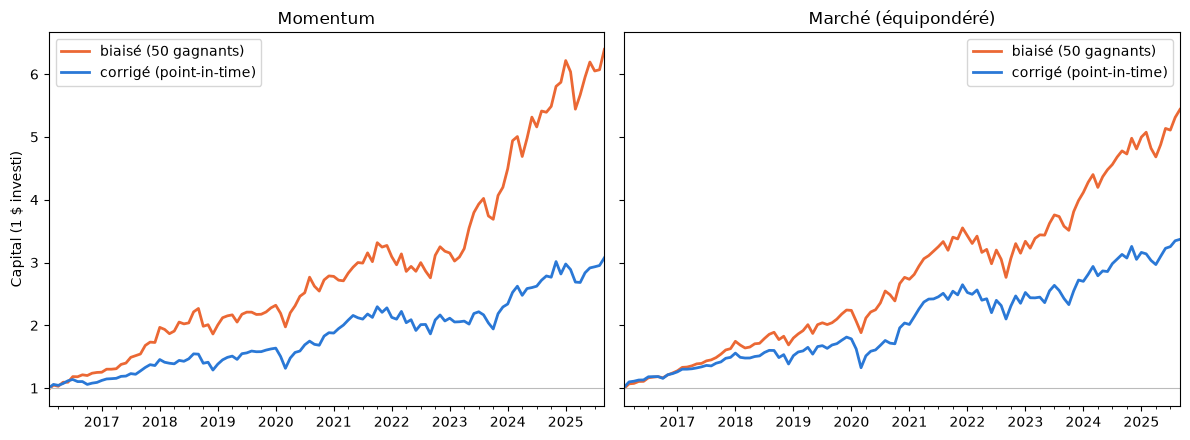

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, col, titre in [(ax1, 'strategy', 'Momentum'), (ax2, 'benchmark', 'Marché (équipondéré)')]:
    equity_curve(bt_biais.loc[common, col]).plot(ax=ax, color=BIAIS, lw=2, label='biaisé (50 gagnants)')
    equity_curve(bt_corr.loc[common, col]).plot(ax=ax, color=CORR, lw=2, label='corrigé (point-in-time)')
    ax.set_title(titre)
    ax.set_xlabel('')
    ax.axhline(1, color='#bbb', lw=0.8)
    ax.legend()
ax1.set_ylabel("Capital (1 $ investi)")
plt.tight_layout()
plt.show()

## 5. Le coût du biais

On isole l'écart que le biais ajoute faussement : différence de rendement annualisé et de Sharpe entre univers biaisé et corrigé.


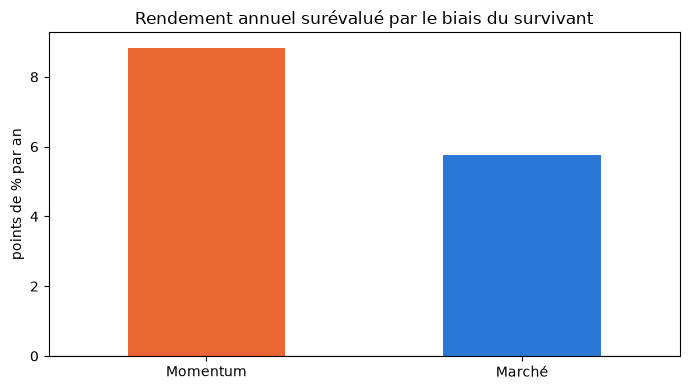

,Δ rendement annuel,Δ Sharpe
Momentum,0.088,0.393
Marché,0.058,0.436


In [6]:
cout = pd.DataFrame({
    'Momentum': metrics(bt_biais, 'strategy') - metrics(bt_corr, 'strategy'),
    'Marché':   metrics(bt_biais, 'benchmark') - metrics(bt_corr, 'benchmark'),
}).T[['rendement_annuel', 'sharpe']]
cout.columns = ['Δ rendement annuel', 'Δ Sharpe']

fig, ax = plt.subplots(figsize=(7, 4))
(cout['Δ rendement annuel'] * 100).plot.bar(ax=ax, color=[BIAIS, CORR], width=0.5)
ax.set_title("Rendement annuel surévalué par le biais du survivant")
ax.set_ylabel("points de % par an")
ax.axhline(0, color='#333', lw=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

cout

## Conclusion

Le biais du survivant **gonfle fortement** les performances : corriger l'univers retire plusieurs points de rendement annuel et abaisse nettement le Sharpe, pour la stratégie **comme** pour le marché. Les résultats « impressionnants » des notebooks précédents étaient en bonne partie l'illusion de ne regarder que les survivants.

Constat robuste au passage : **le momentum ne bat pas le marché** dans les deux univers — cohérent avec l'attribution factorielle (notebook 05).

Limites : la couverture yfinance (~82 %) laisse de côté certains radiés sans prix gratuits ; un vrai correctif professionnel utiliserait une base sans biais de survie (type CRSP, payante). Le présent correctif est *honnête et documenté*, pas parfait.
